# UAV Energy Prediction — EDA, Cleaning, Feature Selection and Split



**Order:** Load → Overview → Define features → Outlier detection & removal → Flight-level EDA → Split → Missing value analysis → Feature filtering → Correlation → MI → Feature report → Select features → Target distribution → Correlation matrix → Save

## 1. Load Libraries and Dataset

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer

#────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
DATA_PATH   = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_ml_ready_10hz_expanded.csv")
PROJECT_DIR = DATA_PATH.parents[1]
EDA_DIR     = PROJECT_DIR / "eda_outputs"
SPLIT_DIR   = PROJECT_DIR / "splits"
for d in [EDA_DIR, SPLIT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)
print("Flights:", df["log_id"].nunique())
print(df["dataset_label"].value_counts())
display(df.head())

Shape: (1019991, 378)
Flights: 172
dataset_label
normal      719371
abnormal    300620
Name: count, dtype: int64


,log_id,dataset_label,time_td,actuator_outputs__noutputs,actuator_outputs__output[0],actuator_outputs__output[1],actuator_outputs__output[2],actuator_outputs__output[3],actuator_outputs__output[4],actuator_outputs__output[5],...,vehicle_status__usb_connected,vehicle_status__open_drone_id_system_present,vehicle_status__open_drone_id_system_healthy,vehicle_status__parachute_system_present,vehicle_status__parachute_system_healthy,vehicle_status__avoidance_system_required,vehicle_status__avoidance_system_valid,vehicle_status__rc_calibration_in_progress,vehicle_status__calibration_enabled,vehicle_status__pre_flight_checks_pass
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Basic Dataset Overview

In [5]:
dataset_summary = pd.DataFrame({
    "Metric": ["Total rows","Total columns","Unique flight logs","Normal rows",
               "Abnormal rows","Normal flight logs","Abnormal flight logs","Sampling rate","Main target"],
    "Value": [df.shape[0], df.shape[1], df["log_id"].nunique(),
              df[df["dataset_label"]=="normal"].shape[0],
              df[df["dataset_label"]=="abnormal"].shape[0],
              df[df["dataset_label"]=="normal"]["log_id"].nunique(),
              df[df["dataset_label"]=="abnormal"]["log_id"].nunique(),
              "10 Hz", "target_energy_next_60s_wh"]
})
display(dataset_summary)
dataset_summary.to_csv(EDA_DIR / "01_dataset_summary.csv", index=False)

,Metric,Value
0,Total rows,1019991
1,Total columns,378
2,Unique flight logs,172
3,Normal rows,719371
4,Abnormal rows,300620
5,Normal flight logs,129
6,Abnormal flight logs,43
7,Sampling rate,10 Hz
8,Main target,target_energy_next_60s_wh


## 3. Define Target Column and Feature Lists

In [6]:
target_col = "target_energy_next_60s_wh"
non_feature_cols = ["log_id", "dataset_label", "time_td"]
leakage_cols     = ["target_energy_next_60s_wh", "future_cumulative_energy_wh", "future_remaining_60s", "target_remaining_drop_60s"]
cols_to_exclude  = non_feature_cols + leakage_cols

allowed_core_features = [
    "time_s",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__current_average_a",
    "battery_status__remaining",
    "battery_status__discharged_mah",
    "power_w",
    "energy_increment_wh",
    "cumulative_energy_wh"
]

print("Target:", target_col, "| exists:", target_col in df.columns)
print("\nCore features available:")
for col in allowed_core_features:
    print(f"  {col}: {col in df.columns}")

Target: target_energy_next_60s_wh | exists: True

Core features available:
  time_s: True
  battery_status__voltage_v: True
  battery_status__voltage_filtered_v: True
  battery_status__current_a: True
  battery_status__current_filtered_a: True
  battery_status__current_average_a: True
  battery_status__remaining: True
  battery_status__discharged_mah: True
  power_w: True
  energy_increment_wh: True
  cumulative_energy_wh: True


## 4. Outlier Detection and Removal (BEFORE split)

In [7]:
# to find Which normal flights have suspiciously high target values
THRESHOLD = 20  #Wh: physically implausible for a normal 60s window

normal_df  = df[df["dataset_label"] == "normal"].copy()
high_energy = normal_df[normal_df[target_col] > THRESHOLD]

print(f"Rows with target > {THRESHOLD} Wh in NORMAL flights: {len(high_energy):,}")
print(f"  = {100 * len(high_energy) / len(normal_df):.3f}% of normal rows\n")

flight_summary = (
    high_energy.groupby("log_id")
    .agg(n_high_rows=(target_col, "count"),
         max_target=(target_col, "max"),
         mean_target=(target_col, "mean"),
         p95_target=(target_col, lambda x: x.quantile(0.95)))
    .sort_values("max_target", ascending=False)
    .reset_index()
)
print(f"Flights affected: {len(flight_summary)} / {normal_df['log_id'].nunique()} normal flights\n")
print(flight_summary.to_string(index=False))

Rows with target > 20 Wh in NORMAL flights: 22,062
  = 3.067% of normal rows

Flights affected: 1 / 129 normal flights

                              log_id  n_high_rows  max_target  mean_target  p95_target
e68d22d7-7b96-4767-a074-edfca1c7f78c        22062   66.087665    52.342273   55.178231


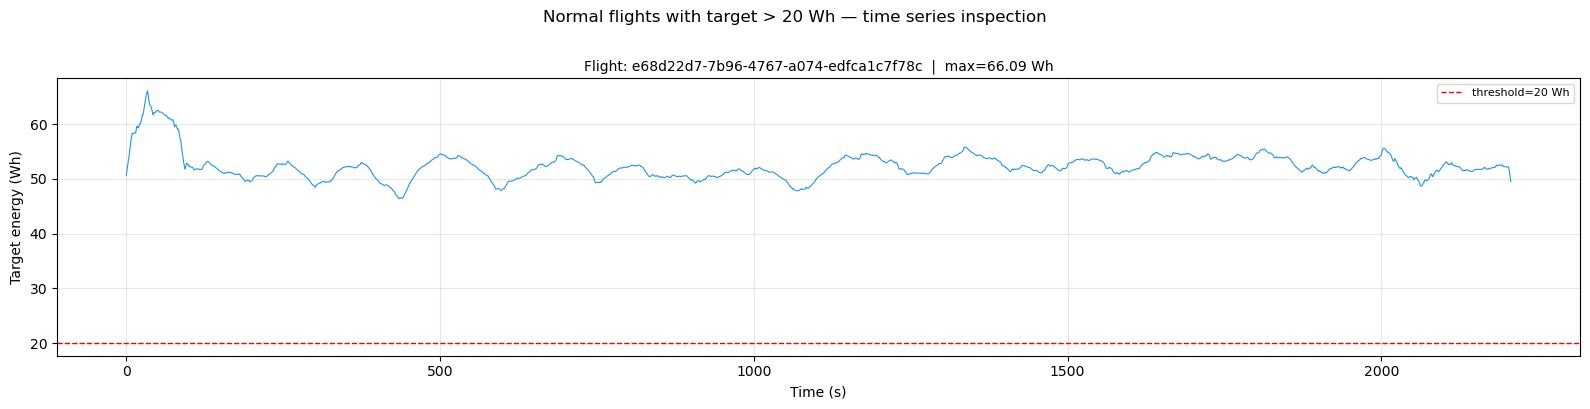

In [8]:
#Time-series plot of suspected flights
suspect_flights = flight_summary["log_id"].tolist()
n_plots = min(4, len(suspect_flights))

fig, axes = plt.subplots(n_plots, 1, figsize=(16, 4 * n_plots))
if n_plots == 1:
    axes = [axes]

for ax, fid in zip(axes, suspect_flights[:4]):
    fd = normal_df[normal_df["log_id"] == fid].sort_values("time_s")
    ax.plot(fd["time_s"], fd[target_col], linewidth=0.8, color="#2196F3")
    ax.axhline(THRESHOLD, color="red", linestyle="--", linewidth=1, label=f"threshold={THRESHOLD} Wh")
    ax.set_title(f"Flight: {fid}  |  max={fd[target_col].max():.2f} Wh", fontsize=10)
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Target energy (Wh)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.suptitle("Normal flights with target > 20 Wh — time series inspection", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_timeseries_suspect_flights.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Flight-Level EDA (run on clean df)

IQR Method
  Q1=0.2779  Q3=3.0706  IQR=2.7926
  Outlier upper bound (Q3+3xIQR): 11.4485 Wh
  Rows above threshold: 22,062 (3.067%)

Z-score Method (|z|>3)
  Rows flagged: 22,062 (3.067%)
  Min flagged value: 46.4028 Wh

Percentile Breakdown
  p90: 3.6068 Wh
  p95: 5.3111 Wh
  p99: 53.0762 Wh
  p99.5: 54.0081 Wh
  p99.9: 58.3473 Wh
  p100: 66.0877 Wh


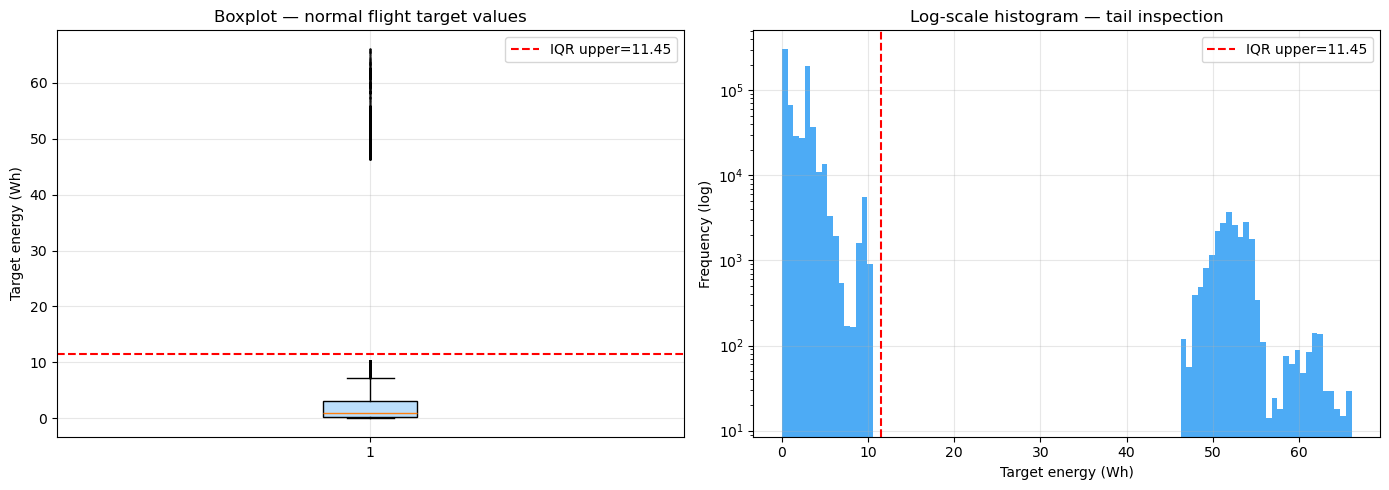

In [9]:
#IQR + Z-score statistical outlier test

target_vals = normal_df[target_col].dropna()
Q1, Q3 = target_vals.quantile(0.25), target_vals.quantile(0.75)
IQR = Q3 - Q1
iqr_upper = Q3 + 3 * IQR
z_scores = np.abs(stats.zscore(target_vals))

print("IQR Method")
print(f"  Q1={Q1:.4f}  Q3={Q3:.4f}  IQR={IQR:.4f}")
print(f"  Outlier upper bound (Q3+3xIQR): {iqr_upper:.4f} Wh")
print(f"  Rows above threshold: {(target_vals > iqr_upper).sum():,} ({100*(target_vals>iqr_upper).mean():.3f}%)")
print("\nZ-score Method (|z|>3)")
print(f"  Rows flagged: {(z_scores>3).sum():,} ({100*(z_scores>3).mean():.3f}%)")
if (z_scores>3).any():
    print(f"  Min flagged value: {target_vals[z_scores>3].min():.4f} Wh")
print("\nPercentile Breakdown")
for p in [90, 95, 99, 99.5, 99.9, 100]:
    print(f"  p{p}: {np.percentile(target_vals, p):.4f} Wh")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.boxplot(target_vals, vert=True, patch_artist=True,
            boxprops=dict(facecolor="#BBDEFB"),
            flierprops=dict(marker=".", markersize=1, alpha=0.3))
ax1.axhline(iqr_upper, color="red", linestyle="--", label=f"IQR upper={iqr_upper:.2f}")
ax1.set_title("Boxplot — normal flight target values")
ax1.set_ylabel("Target energy (Wh)"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.hist(target_vals, bins=100, color="#2196F3", alpha=0.8, edgecolor="none", log=True)
ax2.axvline(iqr_upper, color="red", linestyle="--", label=f"IQR upper={iqr_upper:.2f}")
ax2.set_title("Log-scale histogram — tail inspection")
ax2.set_xlabel("Target energy (Wh)"); ax2.set_ylabel("Frequency (log)"); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_iqr_zscore_test.png", dpi=150)
plt.show()

Top 20 high-target rows with their power_w values:
                              log_id  time_s   power_w  energy_increment_wh  cumulative_energy_wh  target_energy_next_60s_wh
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.6 3593.2422             0.099812             23.708082                  66.087665
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.7 3593.2422             0.099812             23.807894                  66.071539
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.8 3387.1223             0.094087             23.901981                  66.061138
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.5 3226.6917             0.089630             23.608269                  66.060095
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.9 3387.1223             0.094087             23.996067                  66.026597
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.4 3226.6917             0.089630             23.518639                  66.022343
e68d22d7-7b96-4767-a074-edfca1c7f78c    34.0 3477.0989             0.09658

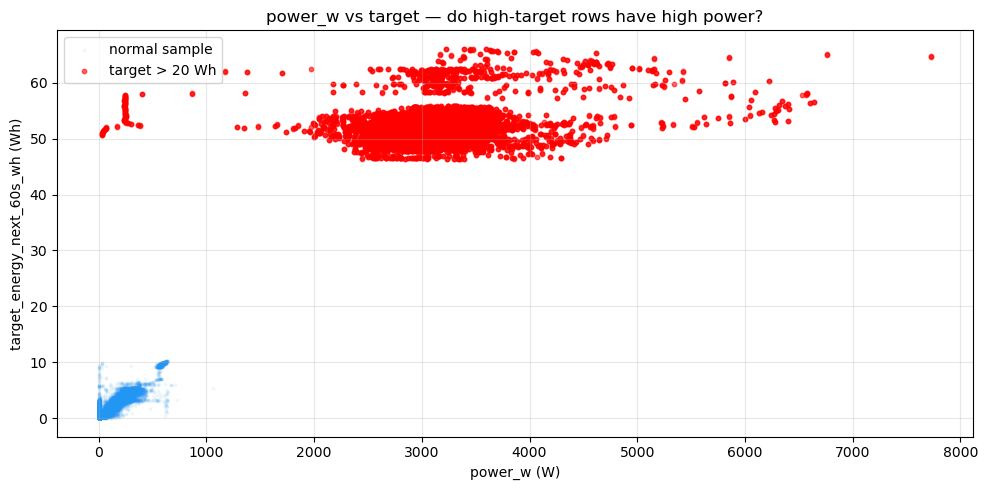

In [10]:
#to Find normal-labelled rows where the next 60 seconds of energy use looks too high.
high_rows = normal_df[normal_df[target_col] > THRESHOLD][
    ["log_id", "time_s", "power_w", "energy_increment_wh", "cumulative_energy_wh", target_col]
].sort_values(target_col, ascending=False)

print("Top 20 high-target rows with their power_w values:")
print(high_rows.head(20).to_string(index=False))
print(f"\n  mean power_w (outlier rows)   : {high_rows['power_w'].mean():.2f} W") #Average power where target is suspiciously high
print(f"  max  power_w (outlier rows)   : {high_rows['power_w'].max():.2f} W") #Highest power in those suspicious rows
print(f"  Normal fleet mean power_w     : {normal_df['power_w'].mean():.2f} W") #Average power across all normal rows
print(f"  Normal fleet 99 percentile  power_w     : {normal_df['power_w'].quantile(0.99):.2f} W") #99th percentile power in normal data

fig, ax = plt.subplots(figsize=(10, 5))
sample = normal_df.sample(min(50000, len(normal_df)), random_state=42)
ax.scatter(sample["power_w"], sample[target_col], alpha=0.05, s=3, color="#2196F3", label="normal sample")
ax.scatter(high_rows["power_w"], high_rows[target_col], alpha=0.6, s=10, color="red", label=f"target > {THRESHOLD} Wh")
ax.set_xlabel("power_w (W)"); ax.set_ylabel("target_energy_next_60s_wh (Wh)")
ax.set_title("power_w vs target — do high-target rows have high power?")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_power_vs_target.png", dpi=150)
plt.show()

## 6. Target distribution analysis

In [11]:
before_shape = df.shape
before_flights = df["log_id"].nunique()

suspect_flights = flight_summary["log_id"].dropna().unique().tolist()
df = df[~df["log_id"].isin(suspect_flights)].copy()

print("Before shape:", before_shape)
print("After shape:", df.shape)
print("Flights removed:", before_flights - df["log_id"].nunique())

Before shape: (1019991, 378)
After shape: (997929, 378)
Flights removed: 1


During EDA, one normal-labelled flight produced extremely high next-60-second energy targets, with values above 60 Wh. Results showed that these rows also had very high instantaneous power, with an average power of approximately 3133 W compared with the normal fleet mean of 193 W. This suggests that the high target values were physically consistent with the measured power draw, but the flight behaved very differently from the majority of normal flights. Therefore, it was flagged as a high-energy outlier rather than treated as a typical normal flight.

## 7. Flight-Level EDA (run on clean df)

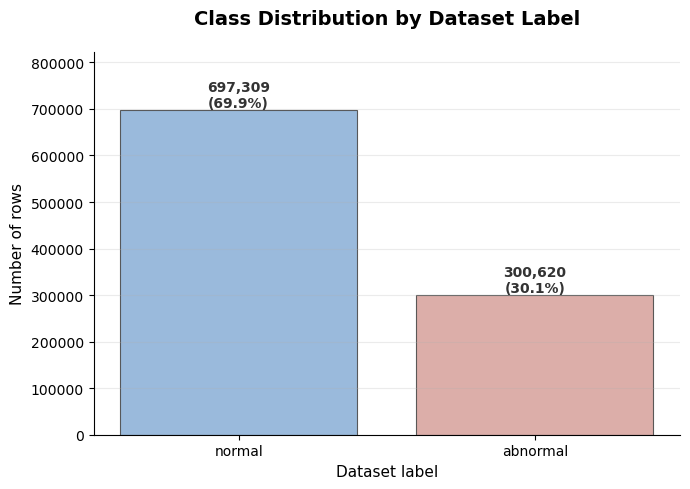

dataset_label
normal      697309
abnormal    300620
Name: count, dtype: int64


In [12]:
#Class imbalance bar chart

label_counts = df["dataset_label"].value_counts()
total_rows = label_counts.sum()
percentages = (label_counts / total_rows) * 100


soft_colors = ["#8FB3D9", "#D9A5A0"] 

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    label_counts.index,
    label_counts.values,
    color=soft_colors,
    edgecolor="#4A4A4A",
    linewidth=0.8,
    alpha=0.9
)

for bar, count, pct in zip(bars, label_counts.values, percentages.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#333333"
    )

ax.set_title("Class Distribution by Dataset Label", fontsize=14, fontweight="bold", pad=20)
ax.set_xlabel("Dataset label", fontsize=11)
ax.set_ylabel("Number of rows", fontsize=11)

ax.set_ylim(0, label_counts.max() * 1.18)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print(label_counts)

## 8. Target distribution analysis

=== TARGET DISTRIBUTION ANALYSIS ===
count    971822.0000
mean          2.3704
std           3.5056
min           0.0000
25%           0.2612
50%           1.4785
75%           3.1489
max          27.5020
Name: target_energy_next_60s_wh, dtype: float64

Skewness : 3.8799
Kurtosis : 19.1032


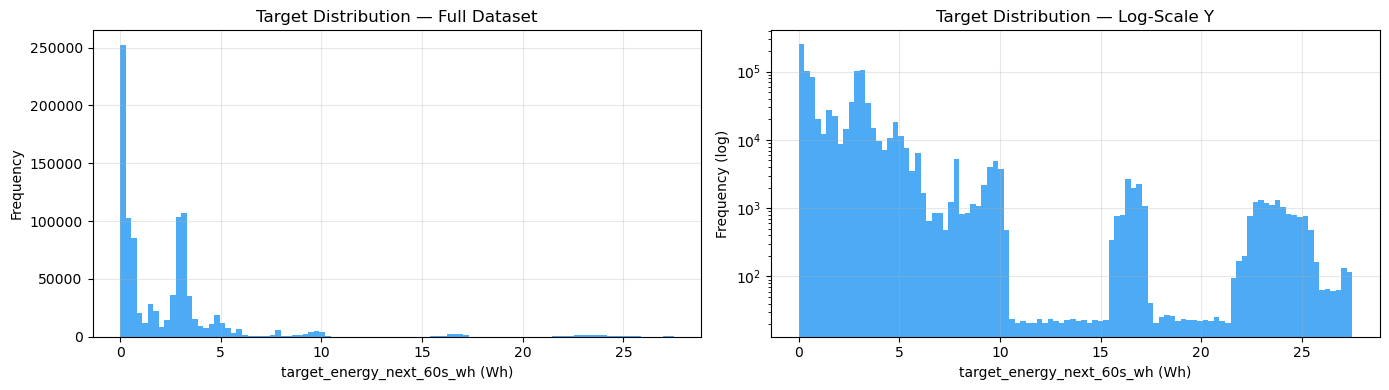

In [40]:
# Section 5b: Target variable distribution analysis
print("=== TARGET DISTRIBUTION ANALYSIS ===")
print(df[target_col].describe().round(4))
print(f"\nSkewness : {df[target_col].skew():.4f}")
print(f"Kurtosis : {df[target_col].kurt():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df[target_col], bins=100, color="#2196F3", alpha=0.8, edgecolor="none")
axes[0].set_title("Target Distribution — Full Dataset")
axes[0].set_xlabel("target_energy_next_60s_wh (Wh)")
axes[0].set_ylabel("Frequency")
axes[0].grid(alpha=0.3)

axes[1].hist(df[target_col], bins=100, color="#2196F3", alpha=0.8, edgecolor="none", log=True)
axes[1].set_title("Target Distribution — Log-Scale Y")
axes[1].set_xlabel("target_energy_next_60s_wh (Wh)")
axes[1].set_ylabel("Frequency (log)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(EDA_DIR / "target_distribution.png", dpi=150)
plt.show()

## 9. Normal vs Abnormal EDA comparison

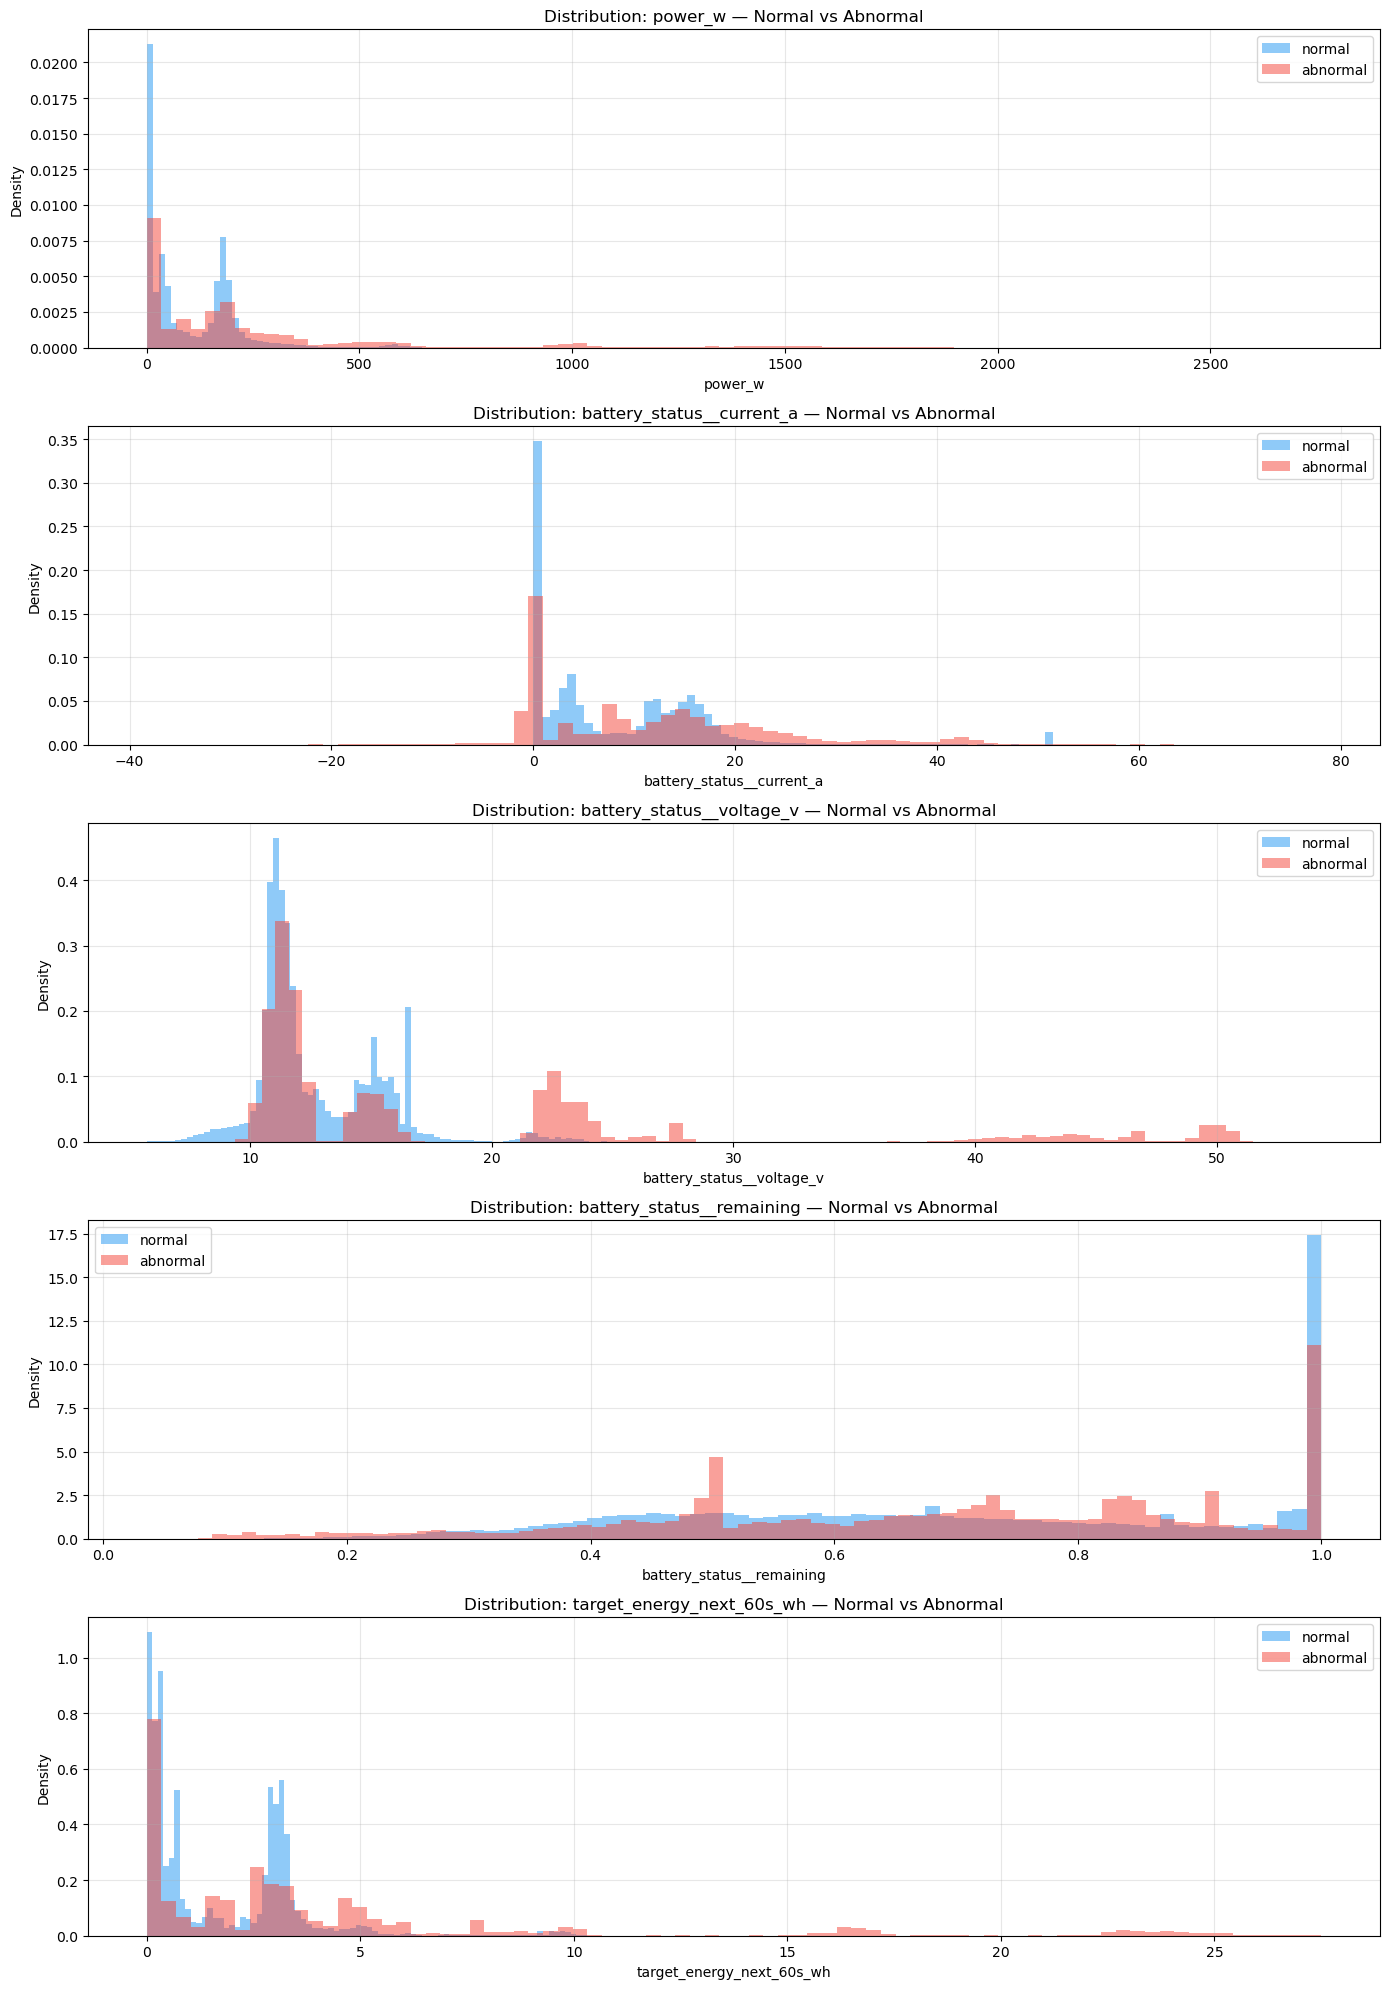


Median values — Normal vs Abnormal:
dataset_label              abnormal   normal
power_w                    150.9856  51.7438
battery_status__current_a    9.2087   4.6624
battery_status__voltage_v   12.3888  11.6405
battery_status__remaining    0.7111   0.6915
target_energy_next_60s_wh    2.6381   0.7862


In [41]:
compare_features = ["power_w", "battery_status__current_a", "battery_status__voltage_v",
                    "battery_status__remaining", target_col]
compare_features = [f for f in compare_features if f in df.columns]

fig, axes = plt.subplots(len(compare_features), 1, figsize=(14, 4 * len(compare_features)))

for ax, feat in zip(axes, compare_features):
    for label, color in [("normal", "#2196F3"), ("abnormal", "#F44336")]:
        vals = df[df["dataset_label"] == label][feat].dropna()
        ax.hist(vals, bins=80, alpha=0.5, color=color, label=label, edgecolor="none", density=True)
    ax.set_title(f"Distribution: {feat} — Normal vs Abnormal")
    ax.set_xlabel(feat)
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(EDA_DIR / "normal_vs_abnormal_feature_distributions.png", dpi=150)
plt.show()

# Print median comparison table
print("\nMedian values — Normal vs Abnormal:")
median_table = df.groupby("dataset_label")[compare_features].median().round(4)
print(median_table.T.to_string())

In [42]:
# Voltage range check — are abnormal flights a different airframe?
print("=== VOLTAGE RANGE BY LABEL ===")
for label in ["normal", "abnormal"]:
    v = df[df["dataset_label"] == label]["battery_status__voltage_v"]
    print(f"\n{label}:")
    print(f"  min={v.min():.2f}V  max={v.max():.2f}V  median={v.median():.2f}V")
    print(f"  Rows with voltage > 25V: {(v > 25).sum():,} ({100*(v>25).mean():.1f}%)")

=== VOLTAGE RANGE BY LABEL ===

normal:
  min=5.72V  max=24.75V  median=11.64V
  Rows with voltage > 25V: 0 (0.0%)

abnormal:
  min=9.35V  max=54.33V  median=12.39V
  Rows with voltage > 25V: 36,738 (13.1%)


## 10. Flight duration distribution per label

count    997929.0000
mean          2.4063
std           3.4681
min           0.0000
25%           0.2705
50%           1.6308
75%           3.1766
max          27.5020
Name: target_energy_next_60s_wh, dtype: float64

Skewness : 3.8738
Kurtosis : 19.3116


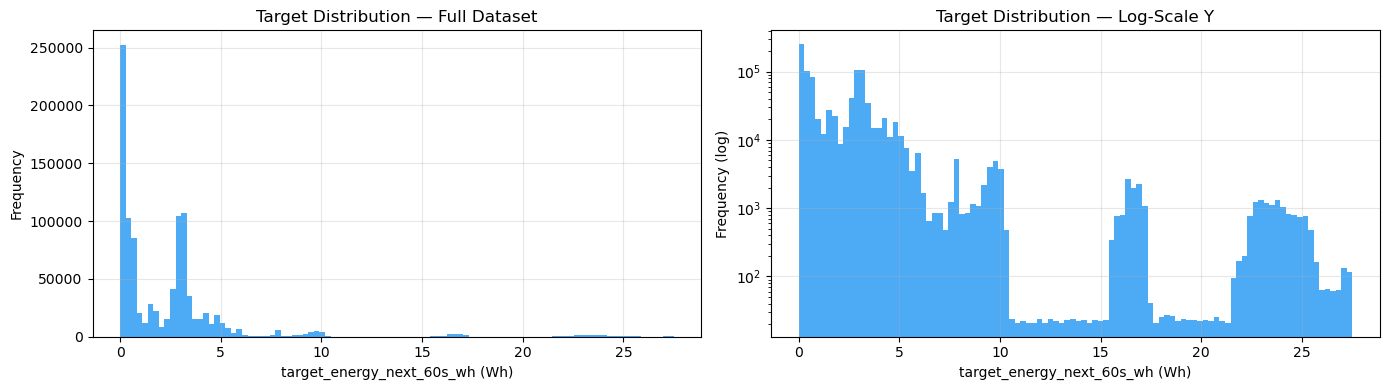

In [ ]:
## 20. Correlation Matrix — Final Features + Target

Flight duration (seconds) by label:
               count   mean    std    min    25%    50%    75%     max
dataset_label                                                         
abnormal        43.0  700.3  418.4  249.6  431.4  570.6  814.2  1924.3
normal         128.0  546.2  304.7  249.2  375.6  434.8  662.6  2391.3


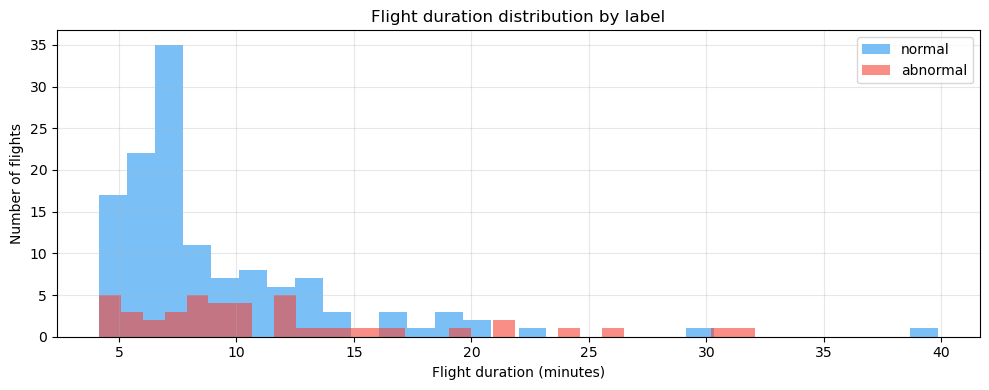

In [ ]:
## 21. Final Model-Ready Datasets

## 11. Save All Reports and Datasets

In [15]:
#Sampling Rate Validation for 60-Second Energy Prediction
expected_gap = 0.1
allowed_gap = 0.15

df_sorted = df.sort_values(["log_id", "time_s"]).copy()

df_sorted["time_gap"] = df_sorted.groupby("log_id")["time_s"].diff()

time_gaps = df_sorted["time_gap"].dropna()

gap_summary = pd.DataFrame({
    "Check": [
        "Expected gap for 10 Hz data",
        "Average observed gap",
        "Median observed gap",
        "Smallest observed gap",
        "Largest observed gap",
        "Total time gaps checked",
        "Number of gaps above allowed limit",
        "Percentage of large gaps"
    ],
    "Result": [
        expected_gap,
        round(time_gaps.mean(), 6),
        round(time_gaps.median(), 6),
        round(time_gaps.min(), 6),
        round(time_gaps.max(), 6),
        len(time_gaps),
        (time_gaps > allowed_gap).sum(),
        round((time_gaps > allowed_gap).mean() * 100, 4)
    ]
})

display(gap_summary)

large_gaps = (time_gaps > allowed_gap).sum()

if large_gaps == 0:
    print("Conclusion: The dataset is consistent with 10 Hz sampling.")
    print("This supports the use of 600 rows as a 60-second prediction window.")
else:
    print("Conclusion: Some larger time gaps were found.")
    print("These gaps should be reviewed before using 600 rows as a fixed 60-second window.")

,Check,Result
0,Expected gap for 10 Hz data,0.100000
1,Average observed gap,0.100245
2,Median observed gap,0.100000
3,Smallest observed gap,0.100000
4,Largest observed gap,6.700000
5,Total time gaps checked,997758.000000
6,Number of gaps above allowed limit,411.000000
7,Percentage of large gaps,0.041200


Conclusion: Some larger time gaps were found.
These gaps should be reviewed before using 600 rows as a fixed 60-second window.


In [16]:
#gap review by flight

gap_rows = df_sorted[df_sorted["time_gap"] > allowed_gap].copy()

gap_summary_by_flight = (
    gap_rows.groupby("log_id")
    .agg(
        number_of_gaps=("time_gap", "count"),
        max_gap_s=("time_gap", "max"),
        mean_gap_s=("time_gap", "mean"),
        first_gap_time_s=("time_s", "min"),
        last_gap_time_s=("time_s", "max")
    )
    .reset_index()
    .sort_values("max_gap_s", ascending=False)
)

display(gap_summary_by_flight.head(20))

print("Total flights with gaps:", gap_summary_by_flight["log_id"].nunique())
print("Total gap rows:", len(gap_rows))

,log_id,number_of_gaps,max_gap_s,mean_gap_s,first_gap_time_s,last_gap_time_s
36,5c1b7f3d-57d4-427e-b302-d22956f66f0b,1,6.7,6.700000,7.9,7.9
3,0332fefb-a16f-4ff9-b626-e8a158346ff4,30,2.5,0.980000,167.0,347.3
19,1b9a2fee-db24-4c6d-b88d-ac3950286eae,6,2.0,1.000000,33.7,317.8
7,06b760bf-d457-46b7-84e1-f08c180aefb3,1,2.0,2.000000,561.6,561.6
43,75678c0f-b911-4875-a2cf-bc317c489c22,8,2.0,1.000000,59.3,779.9
49,80bfac4b-fa67-4fc7-8833-7789229fb78f,6,1.5,1.000000,78.3,284.6
4,03a4237b-52e2-4327-8bfd-0f6e4d6de940,6,1.5,1.250000,29.0,308.2
37,66c5f92a-1fd2-4ddb-b9d8-aba8e1dfcacb,15,1.5,0.800000,27.1,776.4
8,08aab983-e7b7-41b0-a3fe-c719f68cc230,8,1.5,0.850000,1023.6,1089.1
30,4259190b-f88c-4416-b276-dd04d854e70f,4,1.5,0.850000,6.3,238.3


Total flights with gaps: 84
Total gap rows: 411


In [17]:
#Removed flights with serious time gaps only

SERIOUS_GAP_THRESHOLD = 2.0 #maybe 1, need to recheck and confirm with time-series plots of affected flights but 10% of the dataset will be lost.

serious_gap_flights = gap_summary_by_flight[
    gap_summary_by_flight["max_gap_s"] > SERIOUS_GAP_THRESHOLD
]["log_id"].tolist()

print("Flights with serious gaps:", len(serious_gap_flights))
print(serious_gap_flights)

before_rows = len(df)
before_flights = df["log_id"].nunique()

df = df[~df["log_id"].isin(serious_gap_flights)].copy()

print("Rows removed:", before_rows - len(df))
print("Flights removed:", before_flights - df["log_id"].nunique())
print("Updated shape:", df.shape)

Flights with serious gaps: 3
['5c1b7f3d-57d4-427e-b302-d22956f66f0b', '0332fefb-a16f-4ff9-b626-e8a158346ff4', '1b9a2fee-db24-4c6d-b88d-ac3950286eae']
Rows removed: 26107
Flights removed: 3
Updated shape: (971822, 378)


A temporal consistency check was performed to verify the 10 Hz sampling structure. Although the dataset was mostly consistent, a small number of flights contained serious time gaps above 2 seconds. These flights were removed because the 60-second prediction target depends on the assumption that 600 rows represent approximately 60 seconds. This step improved the reliability of the final time-series dataset before modelling.

In [18]:
df_sorted = df.sort_values(["log_id", "time_s"]).copy()
df_sorted["time_gap"] = df_sorted.groupby("log_id")["time_s"].diff()

time_gaps = df_sorted["time_gap"].dropna()

print(time_gaps.describe().round(6))
print("Gaps > 0.15s:", (time_gaps > 0.15).sum())
print("Gaps > 2.0s:", (time_gaps > 2.0).sum())

count    971654.000000
mean          0.100212
std           0.012461
min           0.100000
25%           0.100000
50%           0.100000
75%           0.100000
max           2.000000
Name: time_gap, dtype: float64
Gaps > 0.15s: 374
Gaps > 2.0s: 0


In [19]:
required_cols = ["log_id", "dataset_label", "power_w"]

for col in required_cols:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

flight_power_summary = (
    df.groupby(["log_id", "dataset_label"], as_index=False)
      .agg(mean_power_w=("power_w", "mean"))
)

print("Flight power summary created.")
print("Shape:", flight_power_summary.shape)
display(flight_power_summary.head())

Flight power summary created.
Shape: (168, 3)


,log_id,dataset_label,mean_power_w
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,129.512605
1,00a25d12-c11a-46d2-a704-e2abe3fd38c6,abnormal,221.717570
2,022107fb-9d00-47b7-bc42-ea336f7040f3,normal,41.262665
3,0226edf3-a838-48f9-b932-1882f5353d20,normal,301.388797
4,03a4237b-52e2-4327-8bfd-0f6e4d6de940,normal,18.380529


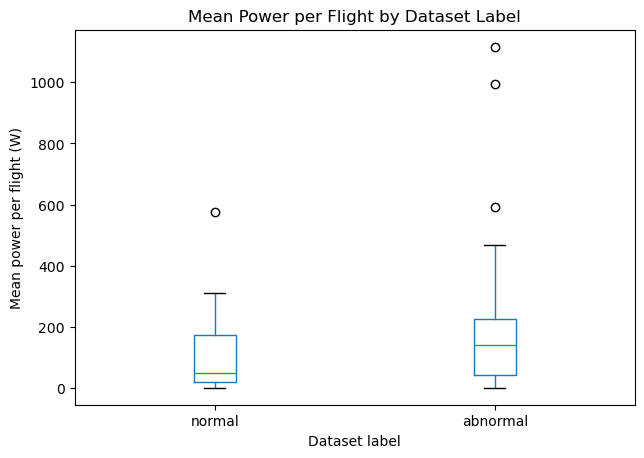

In [20]:
plot_df = flight_power_summary.copy()
plot_df["dataset_label"] = pd.Categorical(
    plot_df["dataset_label"],
    categories=["normal", "abnormal"],
    ordered=True
)

plot_df.boxplot(
    column="mean_power_w",
    by="dataset_label",
    grid=False,
    figsize=(7, 5)
)

plt.title("Mean Power per Flight by Dataset Label")
plt.suptitle("")
plt.xlabel("Dataset label")
plt.ylabel("Mean power per flight (W)")
plt.show()

## 12. Time-gap exclusion log

In [44]:
# Time-gap exclusion summary
MAX_ALLOWED_GAP = 2.0

gap_per_flight = df_sorted.groupby("log_id")["time_gap"].max()
flights_with_large_gap = gap_per_flight[gap_per_flight > MAX_ALLOWED_GAP]

print(f"Flights with any gap > {MAX_ALLOWED_GAP}s: {len(flights_with_large_gap)}")
print(flights_with_large_gap)

rows_before = df.shape[0]
flights_before = df["log_id"].nunique()

df = df[~df["log_id"].isin(flights_with_large_gap.index)].copy()

print(f"\nRows removed : {rows_before - df.shape[0]:,}")
print(f"Flights removed : {flights_before - df['log_id'].nunique()}")
print(f"Remaining rows : {df.shape[0]:,}")
print(f"Remaining flights : {df['log_id'].nunique()}")

Flights with any gap > 2.0s: 0
Series([], Name: time_gap, dtype: float64)

Rows removed : 0
Flights removed : 0
Remaining rows : 971,822
Remaining flights : 168


## 13. dataset for pca

In [21]:
PCA_INPUT_PATH = PROJECT_DIR / "processed_10hz" / "clean_dataset_for_pca.csv"

df.to_csv(PCA_INPUT_PATH, index=False)

print("Saved PCA input dataset:")
print(PCA_INPUT_PATH)
print("Shape:", df.shape)
print("Unique flights:", df["log_id"].nunique())
print("\nLabel distribution:")
print(df["dataset_label"].value_counts())

Saved PCA input dataset:
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_dataset_for_pca.csv
Shape: (971822, 378)
Unique flights: 168

Label distribution:
dataset_label
normal      690380
abnormal    281442
Name: count, dtype: int64


## 14. Train / Val / Test Split (on clean df)

In [22]:
unique_flights = df[["log_id","dataset_label"]].drop_duplicates()

train_flights, temp_flights = train_test_split(
    unique_flights, test_size=0.30, random_state=42,
    stratify=unique_flights["dataset_label"]
)
val_flights, test_flights = train_test_split(
    temp_flights, test_size=0.50, random_state=42,
    stratify=temp_flights["dataset_label"]
)

train_df = df[df["log_id"].isin(train_flights["log_id"])].copy()
val_df   = df[df["log_id"].isin(val_flights["log_id"])].copy()
test_df  = df[df["log_id"].isin(test_flights["log_id"])].copy()

print(f"Train     : {train_df.shape}  | flights: {train_df['log_id'].nunique()}")
print(f"Validation: {val_df.shape}    | flights: {val_df['log_id'].nunique()}")
print(f"Test      : {test_df.shape}   | flights: {test_df['log_id'].nunique()}")

print("\nLabel balance per split:")
for name, split in [("Train",train_df),("Val",val_df),("Test",test_df)]:
    dist = split["dataset_label"].value_counts(normalize=True).round(3)
    print(f"  {name}: {dict(dist)}")

Train     : (694549, 378)  | flights: 117
Validation: (138749, 378)    | flights: 25
Test      : (138524, 378)   | flights: 26

Label balance per split:
  Train: {'normal': np.float64(0.716), 'abnormal': np.float64(0.284)}
  Val: {'normal': np.float64(0.668), 'abnormal': np.float64(0.332)}
  Test: {'normal': np.float64(0.725), 'abnormal': np.float64(0.275)}


In [43]:
# Label ratio check across splits
print("=== LABEL RATIO PER SPLIT ===")
for name, split in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    counts = split["dataset_label"].value_counts()
    pct = (counts / len(split) * 100).round(1)
    print(f"\n{name} ({len(split):,} rows):")
    for label in counts.index:
        print(f"  {label}: {counts[label]:,} ({pct[label]}%)")

=== LABEL RATIO PER SPLIT ===

Train (694,549 rows):
  normal: 497,250 (71.6%)
  abnormal: 197,299 (28.4%)

Val (138,749 rows):
  normal: 92,724 (66.8%)
  abnormal: 46,025 (33.2%)

Test (138,524 rows):
  normal: 100,406 (72.5%)
  abnormal: 38,118 (27.5%)


## 15. Missing Value Report and Heatmap (train_df only)

In [23]:
missing_report = pd.DataFrame({
    "column": train_df.columns,
    "missing_count_train": train_df.isna().sum().values,
    "missing_percent_train": train_df.isna().mean().values * 100,
    "data_type": train_df.dtypes.astype(str).values,
    "unique_values_train": train_df.nunique(dropna=True).values
}).sort_values("missing_percent_train", ascending=False).reset_index(drop=True)

print(f"Columns 100% missing : {(missing_report['missing_percent_train']==100).sum()}")
print(f"Columns >80% missing : {(missing_report['missing_percent_train']>80).sum()}")
print(f"Columns 0% missing   : {(missing_report['missing_percent_train']==0).sum()}")
display(missing_report.head(50))
missing_report.to_csv(EDA_DIR / "03_missing_report_train.csv", index=False)

Columns 100% missing : 247
Columns >80% missing : 342
Columns 0% missing   : 21


,column,missing_count_train,missing_percent_train,data_type,unique_values_train
0,vehicle_status__pre_flight_checks_pass,694549,100.0,float64,0
1,vehicle_gps_position__selected_rtcm_instance,694549,100.0,float64,0
2,vehicle_air_data__time_td,694549,100.0,float64,0
3,vehicle_air_data__rho,694549,100.0,float64,0
4,vehicle_air_data__baro_pressure_pa,694549,100.0,float64,0
5,vehicle_air_data__baro_temp_celcius,694549,100.0,float64,0
6,vehicle_air_data__baro_alt_meter,694549,100.0,float64,0
7,vehicle_gps_position__spoofing_state,694549,100.0,float64,0
8,vehicle_gps_position__rtcm_crc_failed,694549,100.0,float64,0
9,vehicle_attitude__delta_q_reset[1],694549,100.0,float64,0


## 16. Missing value heatmap

In [24]:
MISSING_THRESHOLD = 80

missing_report = pd.DataFrame({
    "column": train_df.columns,
    "missing_count": train_df.isna().sum().values,
    "missing_percent": train_df.isna().mean().values * 100,
    "data_type": train_df.dtypes.astype(str).values,
    "unique_values": train_df.nunique(dropna=True).values
}).sort_values("missing_percent", ascending=False).reset_index(drop=True)

display(missing_report.head(30))


cols_100_missing = missing_report[
    missing_report["missing_percent"] == 100
]["column"].tolist()

cols_high_missing = missing_report[
    missing_report["missing_percent"] > MISSING_THRESHOLD
]["column"].tolist()

print("Columns with 100% missing:", len(cols_100_missing))
print("Columns with >80% missing:", len(cols_high_missing))


cols_to_remove_missing = set(cols_high_missing)

usable_cols_after_missing_filter = [
    col for col in train_df.columns
    if col not in cols_to_remove_missing
]

train_df_missing_filtered = train_df[usable_cols_after_missing_filter].copy()

print("Original train columns:", train_df.shape[1])
print("Columns after missing-value filtering:", train_df_missing_filtered.shape[1])

,column,missing_count,missing_percent,data_type,unique_values
0,vehicle_status__pre_flight_checks_pass,694549,100.0,float64,0
1,vehicle_gps_position__selected_rtcm_instance,694549,100.0,float64,0
2,vehicle_air_data__time_td,694549,100.0,float64,0
3,vehicle_air_data__rho,694549,100.0,float64,0
4,vehicle_air_data__baro_pressure_pa,694549,100.0,float64,0
5,vehicle_air_data__baro_temp_celcius,694549,100.0,float64,0
6,vehicle_air_data__baro_alt_meter,694549,100.0,float64,0
7,vehicle_gps_position__spoofing_state,694549,100.0,float64,0
8,vehicle_gps_position__rtcm_crc_failed,694549,100.0,float64,0
9,vehicle_attitude__delta_q_reset[1],694549,100.0,float64,0


Columns with 100% missing: 247
Columns with >80% missing: 342
Original train columns: 378
Columns after missing-value filtering: 36


Remaining columns with missing values: 15


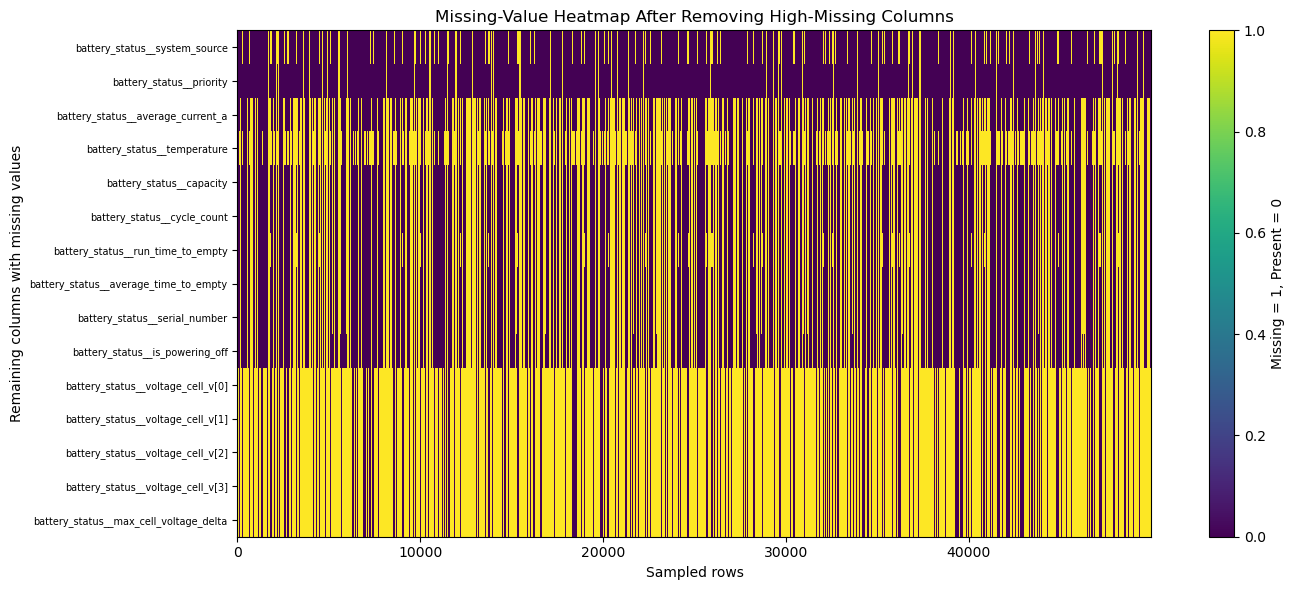

In [25]:
sample_size = min(50000, len(train_df_missing_filtered))

heatmap_sample = train_df_missing_filtered.sample(
    n=sample_size,
    random_state=42
)

missing_matrix = heatmap_sample.isna().astype(int)

# Only plot columns that still have at least some missing values
cols_with_remaining_missing = missing_matrix.columns[
    missing_matrix.sum() > 0
].tolist()

print("Remaining columns with missing values:", len(cols_with_remaining_missing))

if len(cols_with_remaining_missing) == 0:
    print("No remaining missing values after filtering.")
else:
    plt.figure(figsize=(14, 6))
    plt.imshow(
        missing_matrix[cols_with_remaining_missing].T,
        aspect="auto",
        interpolation="nearest"
    )

    plt.title("Missing-Value Heatmap After Removing High-Missing Columns")
    plt.xlabel("Sampled rows")
    plt.ylabel("Remaining columns with missing values")
    plt.yticks(
        ticks=range(len(cols_with_remaining_missing)),
        labels=cols_with_remaining_missing,
        fontsize=7
    )
    plt.colorbar(label="Missing = 1, Present = 0")
    plt.tight_layout()
    plt.show()

## 17. Feature Candidate Filtering

In [26]:
MISSING_THRESHOLD = 80
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()

candidate_features = []
for col in numeric_cols:
    if col in cols_to_exclude or col == target_col:
        continue
    if train_df[col].isna().mean() * 100 >= MISSING_THRESHOLD:
        continue
    if train_df[col].nunique(dropna=True) <= 1:
        continue
    candidate_features.append(col)

print(f"Candidate features after filtering: {len(candidate_features)}")
print(candidate_features)

Candidate features after filtering: 18
['battery_status__voltage_v', 'battery_status__voltage_filtered_v', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__cell_count', 'battery_status__warning', 'time_s', 'power_w', 'energy_increment_wh', 'cumulative_energy_wh', 'battery_status__system_source', 'battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]']


## 18. Correlation with Target (train_df only)

In [27]:
correlation_rows = []
for col in candidate_features:
    temp = train_df[[col, target_col]].dropna()
    if len(temp) < 100:
        continue
    pearson  = temp[col].corr(temp[target_col], method="pearson")
    spearman = temp[col].corr(temp[target_col], method="spearman")
    correlation_rows.append({
        "column": col,
        "pearson_corr": pearson,
        "abs_pearson_corr": abs(pearson) if pd.notna(pearson) else np.nan,
        "spearman_corr": spearman,
        "abs_spearman_corr": abs(spearman) if pd.notna(spearman) else np.nan
    })

correlation_report = (pd.DataFrame(correlation_rows)
    .sort_values("abs_pearson_corr", ascending=False)
    .reset_index(drop=True))

display(correlation_report.head(40))
correlation_report.to_csv(EDA_DIR / "04_correlation_with_target.csv", index=False)

,column,pearson_corr,abs_pearson_corr,spearman_corr,abs_spearman_corr
0,power_w,0.959160,0.959160,0.911390,0.911390
1,energy_increment_wh,0.959160,0.959160,0.911390,0.911390
2,battery_status__current_filtered_a,0.767930,0.767930,0.830881,0.830881
3,battery_status__current_a,0.755438,0.755438,0.824221,0.824221
4,cumulative_energy_wh,0.713144,0.713144,0.754326,0.754326
5,battery_status__discharged_mah,0.676590,0.676590,0.682577,0.682577
6,battery_status__cell_count,0.674366,0.674366,0.386847,0.386847
7,battery_status__voltage_filtered_v,0.614302,0.614302,0.162379,0.162379
8,battery_status__voltage_v,0.608786,0.608786,0.184333,0.184333
9,battery_status__scale,0.191911,0.191911,0.196894,0.196894


## 19. Mutual Information (train_df only)

In [28]:
MI_SAMPLE = 100_000
mi_sample = train_df[candidate_features + [target_col]].dropna(subset=[target_col]).copy()
if len(mi_sample) > MI_SAMPLE:
    mi_sample = mi_sample.sample(n=MI_SAMPLE, random_state=42)

X_mi = SimpleImputer(strategy="median").fit_transform(mi_sample[candidate_features])
y_mi = mi_sample[target_col]
mi_scores = mutual_info_regression(X_mi, y_mi, random_state=42)

mi_report = (pd.DataFrame({"column": candidate_features, "mutual_information_score": mi_scores})
    .sort_values("mutual_information_score", ascending=False)
    .reset_index(drop=True))

display(mi_report.head(40))
mi_report.to_csv(EDA_DIR / "05_mutual_information.csv", index=False)

,column,mutual_information_score
0,battery_status__discharged_mah,2.535032
1,cumulative_energy_wh,2.518044
2,battery_status__current_filtered_a,2.277911
3,battery_status__voltage_filtered_v,2.116441
4,battery_status__voltage_v,1.809737
5,energy_increment_wh,1.772605
6,power_w,1.772362
7,battery_status__current_a,1.668562
8,battery_status__remaining,1.328827
9,time_s,1.296403


## 20. Select Final Feature Columns

In [29]:
top_corr_features = correlation_report.head(30)["column"].tolist()
top_mi_features   = mi_report.head(30)["column"].tolist()
valid_core        = [c for c in allowed_core_features if c in candidate_features]

final_feature_cols = sorted(set(valid_core + top_corr_features + top_mi_features))

print(f"Final feature count: {len(final_feature_cols)}")
for col in final_feature_cols:
    print(f"  {col}")

Final feature count: 18
  battery_status__cell_count
  battery_status__current_a
  battery_status__current_filtered_a
  battery_status__discharged_mah
  battery_status__remaining
  battery_status__scale
  battery_status__system_source
  battery_status__voltage_cell_v[0]
  battery_status__voltage_cell_v[1]
  battery_status__voltage_cell_v[2]
  battery_status__voltage_cell_v[3]
  battery_status__voltage_filtered_v
  battery_status__voltage_v
  battery_status__warning
  cumulative_energy_wh
  energy_increment_wh
  power_w
  time_s


In [30]:
# Review metadata-like battery features before removal decision

review_cols = [
    "battery_status__cell_count",
    "battery_status__scale",
    "battery_status__system_source",
    "battery_status__warning"
]

print("1. Value distribution")
for col in review_cols:
    print("\n" + "="*70)
    print(col)
    print("Unique values:", df[col].nunique(dropna=True))
    print(df[col].value_counts(dropna=False).head(20))

print("\n\n2. Pearson correlation with target")
corr_results = []

for col in review_cols:
    corr = df[col].corr(df["target_energy_next_60s_wh"])
    corr_results.append({
        "feature": col,
        "pearson_corr_with_target": corr
    })

corr_results_df = pd.DataFrame(corr_results)
display(corr_results_df.sort_values("pearson_corr_with_target", ascending=False))

print("\n\n3. Mutual Information score")
mi_review_df = mi_report[
    mi_report["column"].isin(review_cols)
].sort_values("mutual_information_score", ascending=False)

display(mi_review_df)

1. Value distribution

battery_status__cell_count
Unique values: 5
battery_status__cell_count
3.0     683532
4.0     176295
6.0      78728
12.0     28370
0.0       4897
Name: count, dtype: int64

battery_status__scale
Unique values: 164359
battery_status__scale
1.000000    168169
1.072844     10832
1.072846      2526
1.000157        36
1.001675        30
1.000568        30
1.026662        30
1.026662        30
1.000063        30
1.027592        30
1.000140        29
1.001005        28
1.109957        26
1.044815        26
1.000071        25
1.026724        25
1.001468        25
1.000482        25
1.026770        25
1.028039        25
Name: count, dtype: int64

battery_status__system_source
Unique values: 2
battery_status__system_source
1.0    758939
NaN    151475
0.0     61408
Name: count, dtype: int64

battery_status__warning
Unique values: 4
battery_status__warning
0.0    960081
1.0      9236
3.0      2107
2.0       398
Name: count, dtype: int64


2. Pearson correlation with target


,feature,pearson_corr_with_target
0,battery_status__cell_count,0.643427
1,battery_status__scale,0.140607
2,battery_status__system_source,0.066537
3,battery_status__warning,0.023974




3. Mutual Information score


,column,mutual_information_score
10,battery_status__scale,1.243603
11,battery_status__cell_count,0.588291
16,battery_status__system_source,0.147446
17,battery_status__warning,0.023543


In [31]:
#to Remove weak metadata-like features after review

cols_to_remove = [
    "battery_status__system_source",
    "battery_status__warning"
]

final_feature_cols = [
    col for col in final_feature_cols
    if col not in cols_to_remove
]

print("Removed columns:", cols_to_remove)
print("Updated final feature count:", len(final_feature_cols))

display(pd.DataFrame({
    "No.": range(1, len(final_feature_cols) + 1),
    "Final Feature": final_feature_cols
}))

Removed columns: ['battery_status__system_source', 'battery_status__warning']
Updated final feature count: 16


,No.,Final Feature
0,1,battery_status__cell_count
1,2,battery_status__current_a
2,3,battery_status__current_filtered_a
3,4,battery_status__discharged_mah
4,5,battery_status__remaining
5,6,battery_status__scale
6,7,battery_status__voltage_cell_v[0]
7,8,battery_status__voltage_cell_v[1]
8,9,battery_status__voltage_cell_v[2]
9,10,battery_status__voltage_cell_v[3]


## 21. Target Distribution (on clean df — post outlier removal)

normal: n=690,380  median=0.786  p99=9.225  max=10.309
abnormal: n=281,442  median=2.638  p99=24.689  max=27.502


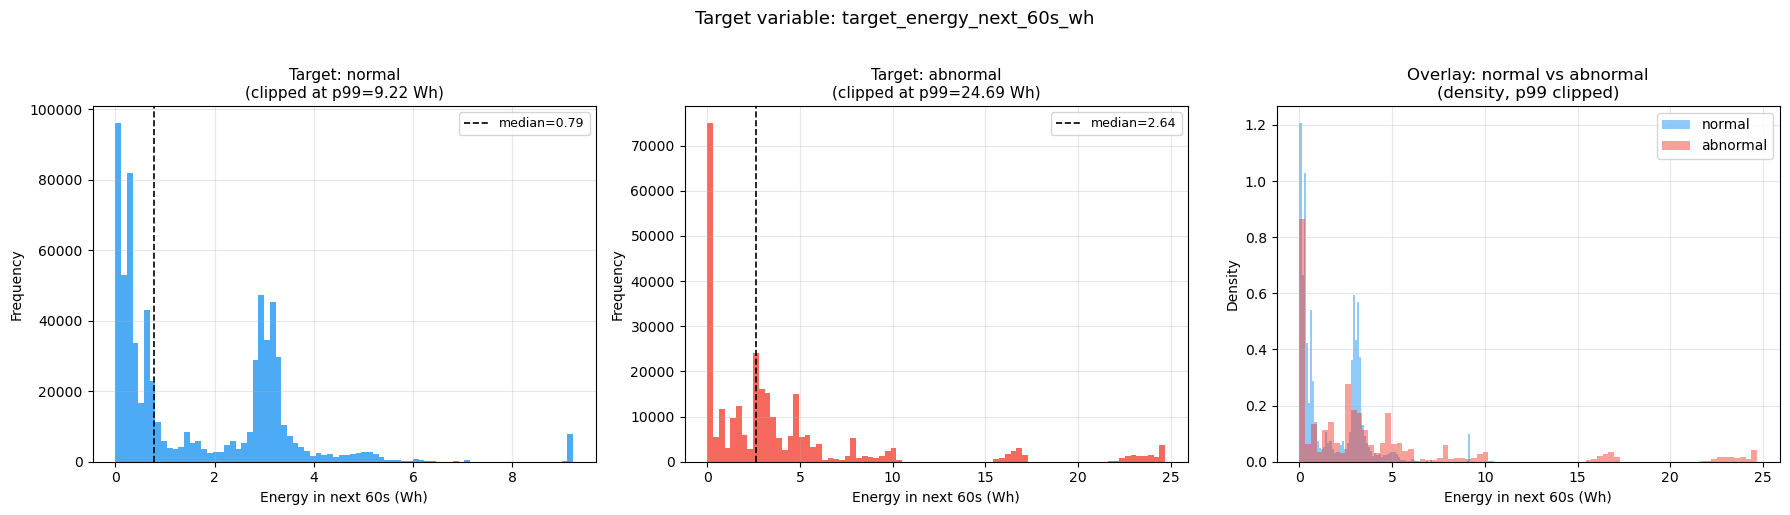

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {"normal":"#2196F3", "abnormal":"#F44336"}

for ax, label in zip(axes[:2], ["normal","abnormal"]):
    subset = df[df["dataset_label"]==label][target_col].dropna()
    p99    = np.percentile(subset, 99)
    clipped = subset.clip(upper=p99)
    print(f"{label}: n={len(subset):,}  median={subset.median():.3f}  p99={p99:.3f}  max={subset.max():.3f}")
    ax.hist(clipped, bins=80, color=colors[label], alpha=0.8, edgecolor="none")
    ax.axvline(subset.median(), color="black", linestyle="--", linewidth=1.2,
               label=f"median={subset.median():.2f}")
    ax.set_title(f"Target: {label}\n(clipped at p99={p99:.2f} Wh)", fontsize=11)
    ax.set_xlabel("Energy in next 60s (Wh)"); ax.set_ylabel("Frequency")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax = axes[2]
for label in ["normal","abnormal"]:
    subset = df[df["dataset_label"]==label][target_col].dropna()
    p99    = np.percentile(subset, 99)
    ax.hist(subset.clip(upper=p99), bins=80, alpha=0.5, label=label,
            color=colors[label], edgecolor="none", density=True)
ax.set_title("Overlay: normal vs abnormal\n(density, p99 clipped)")
ax.set_xlabel("Energy in next 60s (Wh)"); ax.set_ylabel("Density")
ax.legend(); ax.grid(alpha=0.3)

plt.suptitle("Target variable: target_energy_next_60s_wh", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(EDA_DIR / "target_distribution_clean.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
normal_high = df[
    (df["dataset_label"] == "normal") &
    (df["target_energy_next_60s_wh"] > 8)
].copy()

print("Rows:", len(normal_high))
print("Flights:", normal_high["log_id"].nunique())

normal_high.groupby("log_id").agg(
    rows=("target_energy_next_60s_wh", "count"),
    min_target=("target_energy_next_60s_wh", "min"),
    max_target=("target_energy_next_60s_wh", "max"),
    mean_target=("target_energy_next_60s_wh", "mean"),
    mean_power=("power_w", "mean"),
    max_power=("power_w", "max"),
    first_time=("time_s", "min"),
    last_time=("time_s", "max")
).sort_values("max_target", ascending=False)

Rows: 8218
Flights: 2


,rows,min_target,max_target,mean_target,mean_power,max_power,first_time,last_time
log_id,,,,,,,,
670aaff6-ba17-4047-ae2c-53e26d74bf74,3734,8.832687,10.309221,9.763154,576.418168,640.80817,0.0,373.3
bc1ff53c-5aae-430f-9787-f5182e51af31,4484,8.001982,10.036584,9.387799,546.964022,638.72626,466.7,976.7


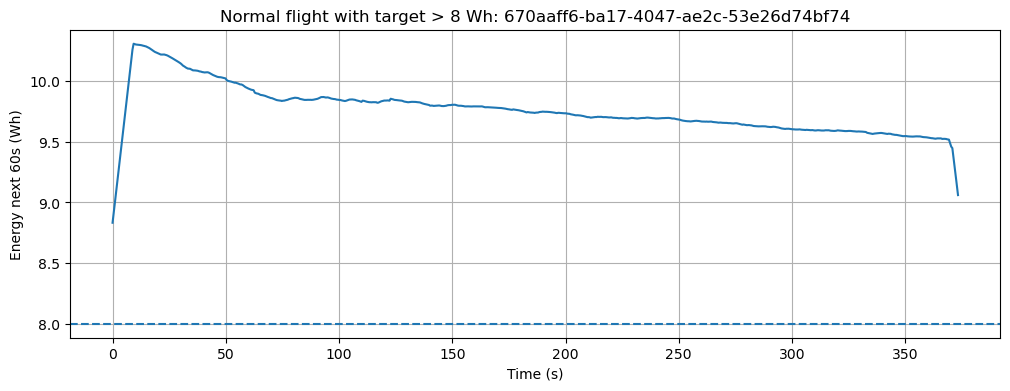

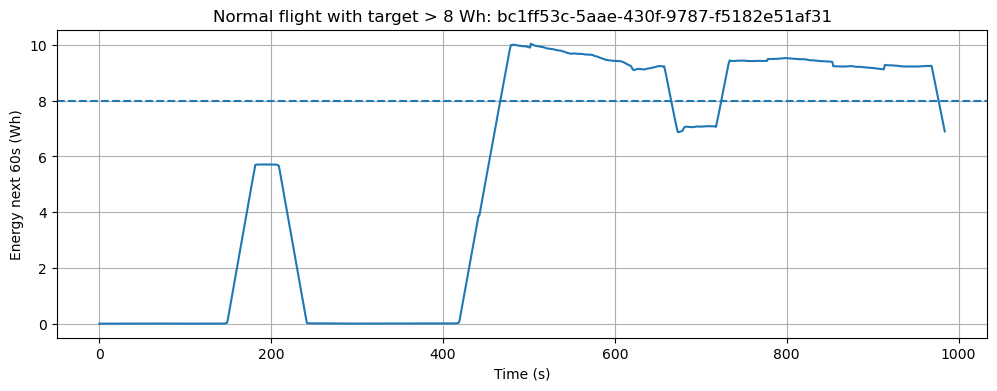

In [34]:
for log in normal_high["log_id"].unique():
    temp = df[df["log_id"] == log]

    plt.figure(figsize=(12,4))
    plt.plot(temp["time_s"], temp["target_energy_next_60s_wh"])
    plt.axhline(8, linestyle="--")
    plt.title(f"Normal flight with target > 8 Wh: {log}")
    plt.xlabel("Time (s)")
    plt.ylabel("Energy next 60s (Wh)")
    plt.grid(True)
    plt.show()

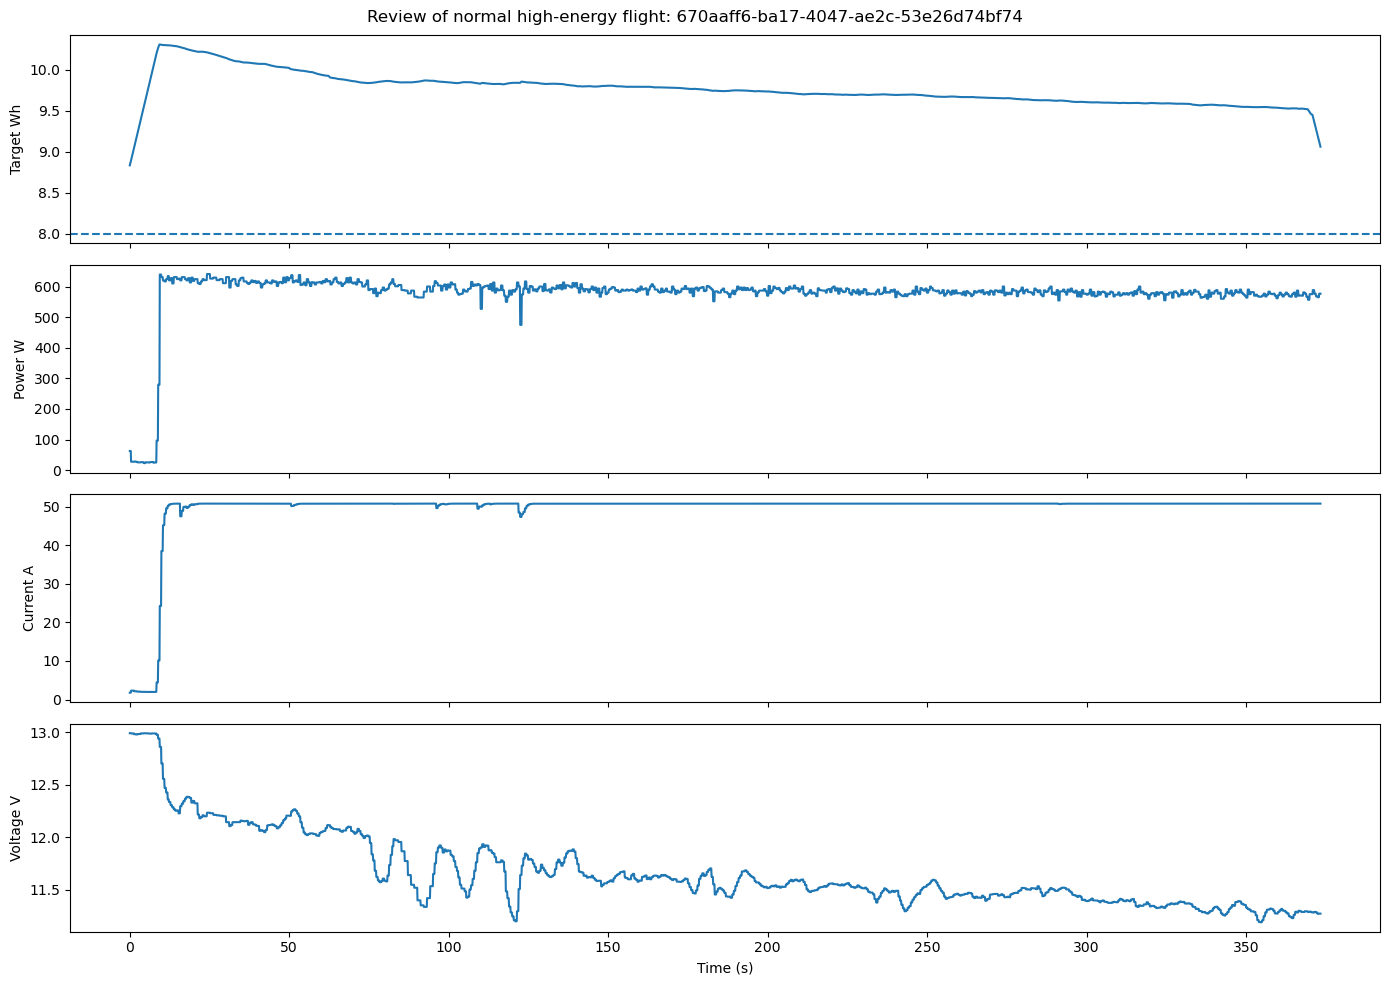

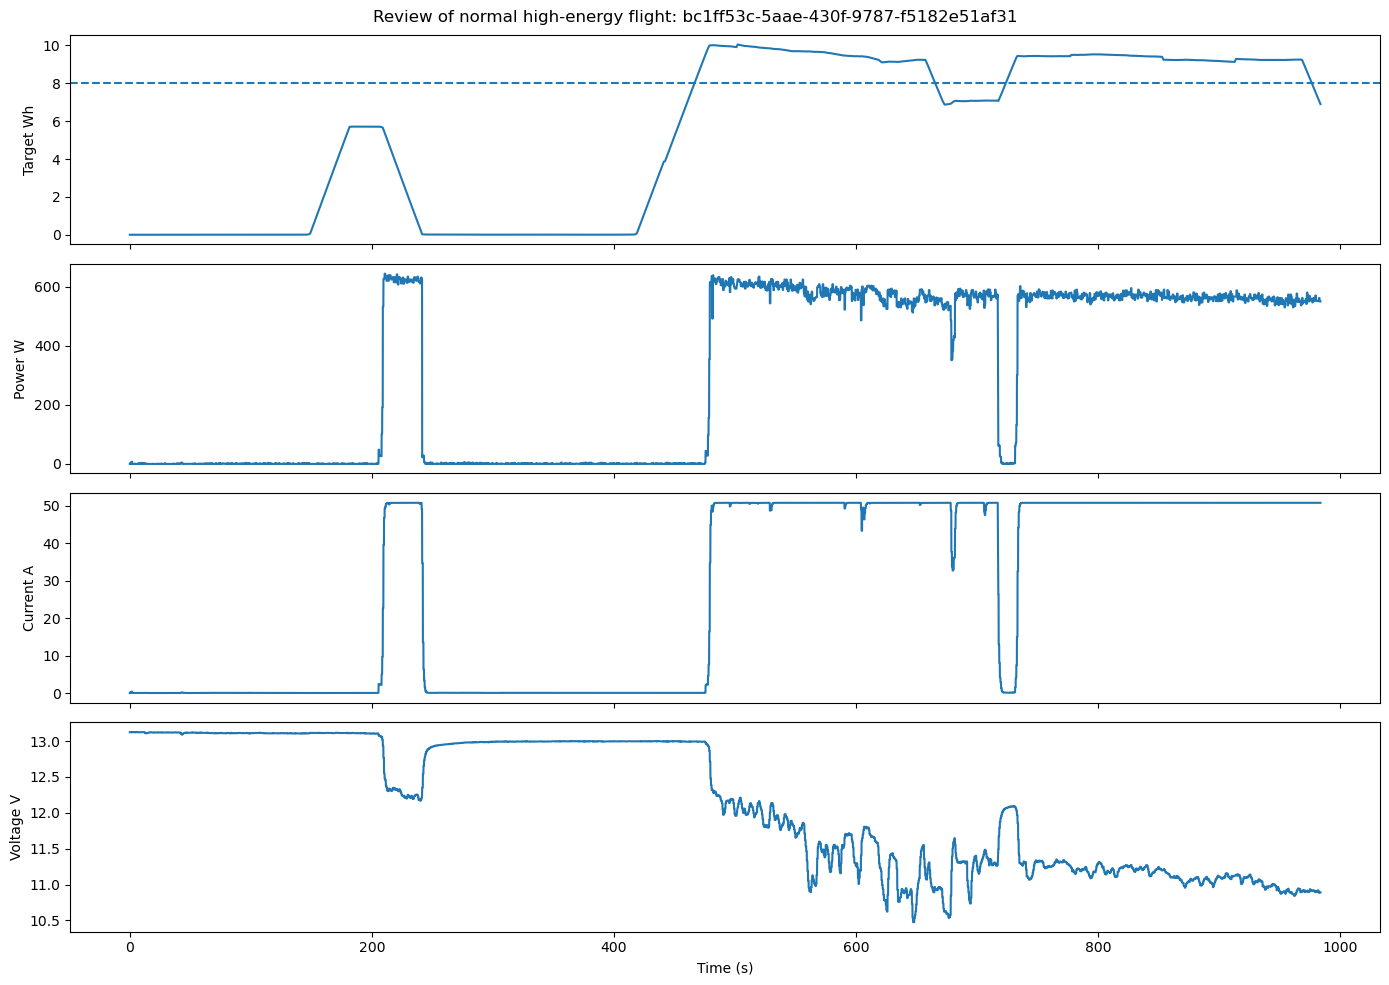

In [35]:
for log in normal_high["log_id"].unique():
    temp = df[df["log_id"] == log].copy()

    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

    axes[0].plot(temp["time_s"], temp["target_energy_next_60s_wh"])
    axes[0].axhline(8, linestyle="--")
    axes[0].set_ylabel("Target Wh")

    axes[1].plot(temp["time_s"], temp["power_w"])
    axes[1].set_ylabel("Power W")

    axes[2].plot(temp["time_s"], temp["battery_status__current_filtered_a"])
    axes[2].set_ylabel("Current A")

    axes[3].plot(temp["time_s"], temp["battery_status__voltage_filtered_v"])
    axes[3].set_ylabel("Voltage V")
    axes[3].set_xlabel("Time (s)")

    plt.suptitle(f"Review of normal high-energy flight: {log}")
    plt.tight_layout()
    plt.show()

## 22. Correlation Matrix — Final Features + Target

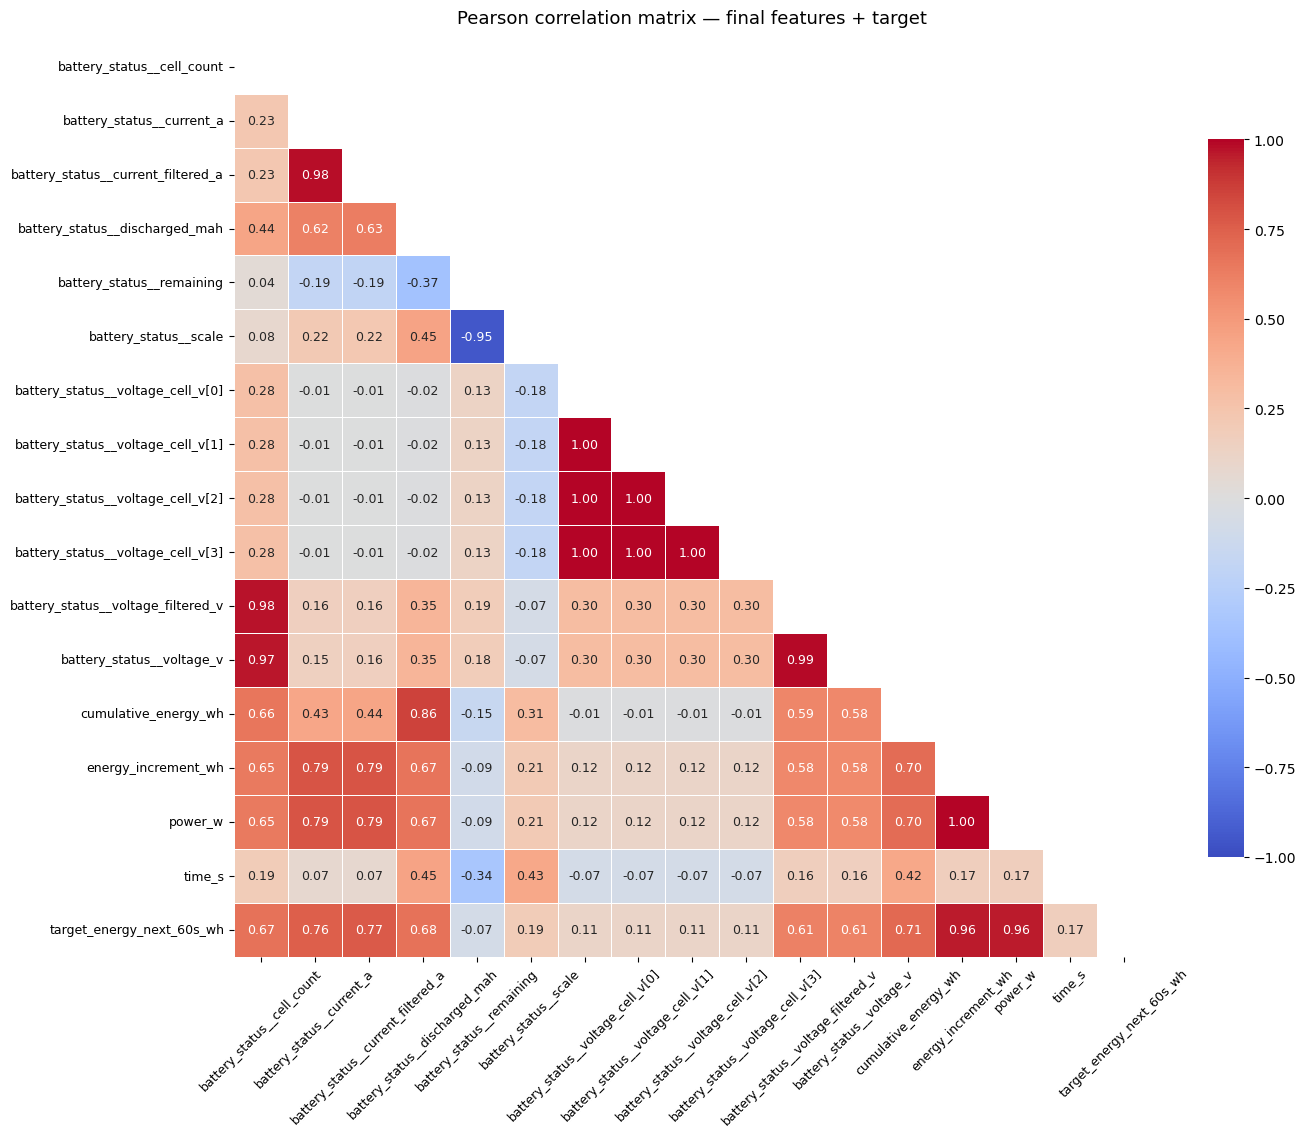


Top correlations with target:
power_w                               0.959160
energy_increment_wh                   0.959160
battery_status__current_filtered_a    0.767930
battery_status__current_a             0.755438
cumulative_energy_wh                  0.713144
battery_status__discharged_mah        0.676590
battery_status__cell_count            0.674366
battery_status__voltage_filtered_v    0.614302
battery_status__voltage_v             0.608786
battery_status__scale                 0.191911
time_s                                0.171814
battery_status__voltage_cell_v[0]     0.113864
battery_status__voltage_cell_v[1]     0.113864
battery_status__voltage_cell_v[2]     0.113864
battery_status__voltage_cell_v[3]     0.113864
battery_status__remaining             0.072543
Name: target_energy_next_60s_wh, dtype: float64


In [36]:
corr_cols   = final_feature_cols + [target_col]
corr_matrix = train_df[corr_cols].corr()
mask        = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr_matrix, ax=ax, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink":0.7}, annot_kws={"size":9})
ax.set_title("Pearson correlation matrix — final features + target", fontsize=13, pad=12)
ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0,  labelsize=9)
plt.tight_layout()
plt.savefig(EDA_DIR / "correlation_matrix_final_features.png", dpi=150)
plt.show()

print("\nTop correlations with target:")
print(corr_matrix[target_col].drop(target_col).abs().sort_values(ascending=False))

## 23. Final Model-Ready Datasets

In [37]:
final_model_cols = ["log_id","dataset_label"] + final_feature_cols + [target_col]
train_model_df   = train_df[final_model_cols].copy()
val_model_df     = val_df[final_model_cols].copy()
test_model_df    = test_df[final_model_cols].copy()

print("Train :", train_model_df.shape)
print("Val   :", val_model_df.shape)
print("Test  :", test_model_df.shape)
display(train_model_df.head())

Train : (694549, 19)
Val   : (138749, 19)
Test  : (138524, 19)


,log_id,dataset_label,battery_status__cell_count,battery_status__current_a,battery_status__current_filtered_a,battery_status__discharged_mah,battery_status__remaining,battery_status__scale,battery_status__voltage_cell_v[0],battery_status__voltage_cell_v[1],battery_status__voltage_cell_v[2],battery_status__voltage_cell_v[3],battery_status__voltage_filtered_v,battery_status__voltage_v,cumulative_energy_wh,energy_increment_wh,power_w,time_s,target_energy_next_60s_wh
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,NaN,NaN,NaN,NaN,11.758164,11.763942,0.000000,0.000000,0.000000,0.0,0.001262
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,NaN,NaN,NaN,NaN,11.758164,11.763942,0.000000,0.000000,0.000000,0.1,0.001262
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,NaN,NaN,NaN,NaN,11.758164,11.763942,0.000000,0.000000,0.000000,0.2,0.001262
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,NaN,NaN,NaN,NaN,11.758164,11.763942,0.000000,0.000000,0.000000,0.3,0.001262
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.46793,0.088367,0.016040,0.784237,1.040576,NaN,NaN,NaN,NaN,11.754977,11.730804,0.000152,0.000152,5.489191,0.4,0.001109


In [38]:
columns_df = pd.DataFrame({
    "No.": range(1, len(train_model_df.columns) + 1),
    "Column Name": train_model_df.columnsFsampling
})

display(columns_df)

,No.,Column Name
0,1,log_id
1,2,dataset_label
2,3,battery_status__cell_count
3,4,battery_status__current_a
4,5,battery_status__current_filtered_a
5,6,battery_status__discharged_mah
6,7,battery_status__remaining
7,8,battery_status__scale
8,9,battery_status__voltage_cell_v[0]
9,10,battery_status__voltage_cell_v[1]


## 24. Save All Reports and Datasets

In [39]:
#Feature reports 
feature_report.to_excel(EDA_DIR / "feature_selection_evidence_report.xlsx", index=False)
correlation_report.to_csv(EDA_DIR / "correlation_with_target_report.csv", index=False)
mi_report.to_csv(EDA_DIR / "mutual_information_report.csv", index=False)

#Model-ready splits 
train_model_df.to_csv(SPLIT_DIR / "train_model_ready_selected_features.csv", index=False)
val_model_df.to_csv(SPLIT_DIR   / "val_model_ready_selected_features.csv",   index=False)
test_model_df.to_csv(SPLIT_DIR  / "test_model_ready_selected_features.csv",  index=False)

print("Saved reports to :", EDA_DIR)
print("Saved splits to  :", SPLIT_DIR)

NameError: name 'feature_report' is not defined